<font size="6">EARLY STEPS IN COLAB. IGNORE AND DO NOT RUN --START

In [ ]:
   from google.colab import drive
   drive.mount('/content/drive')
   %cd /content/drive/MyDrive/PSUPRProject_2026Sem2/bimcv_xray
   !ls

ModuleNotFoundError: No module named 'google.colab'

In [ ]:
#fetch the information of XRAY Covid P and N. The data must be of the patient that doesnt have CT data at all to prevent data leakage.

!python build_xray_only_mapping.py #exclude patient_archive_mapping.csv paired_patient_manifest.csv

Negative: 64 archives, 64 listings on server, 64 already downloaded
Positive: 571 archives, 571 listings on server, 571 already downloaded
Read 635 listings; 34160 patients with an X-ray or CT

Decisions:
   27221  KEEP
    4191  has CT (groupmate side)
    2748  no X-ray
X-ray-only Positive: 24817 patients across 571 archives
X-ray-only Negative: 2404 patients across 64 archives

Mapping: /content/drive/MyDrive/PSUPRProject_2026Sem2/bimcv_xray/xray_work/xray_only_mapping.csv
Archive plan: /content/drive/MyDrive/PSUPRProject_2026Sem2/bimcv_xray/xray_work/xray_only_archives.csv


In [ ]:
!python summarize_xray_only.py


=== Positive
  Patients: 24817   Images: 64672   Images/patient: median 2, max 50
  Archives holding them: 571  (~2,912 GB to get all)
  To reach N patients (best archives first):
      100 patients:    2 archives  ~     10 GB
      200 patients:    3 archives  ~     15 GB
      300 patients:    4 archives  ~     20 GB
      500 patients:    7 archives  ~     36 GB
     1000 patients:   13 archives  ~     66 GB
      all patients:  571 archives  ~  2,912 GB

=== Negative
  Patients: 2404   Images: 4609   Images/patient: median 2, max 18
  Archives holding them: 64  (~326 GB to get all)
  To reach N patients (best archives first):
      100 patients:    2 archives  ~     10 GB
      200 patients:    4 archives  ~     20 GB
      300 patients:    5 archives  ~     26 GB
      500 patients:    9 archives  ~     46 GB
     1000 patients:   19 archives  ~     97 GB
      all patients:   64 archives  ~    326 GB

GB is downloaded traffic; with step 2 deleting each archive after use, you onl

In [ ]:
#check PA AP split for the above XRAY data

import csv, re, collections, pathlib
work = pathlib.Path('xray_work')
group, status = {}, {}
for r in csv.DictReader(open(work/'all_patients_modalities.csv')):
    if r['Decision'] == 'KEEP':                       group[r['Patient ID']] = 'xray_only'
    elif r['Decision'].startswith('has CT') and int(r['X-ray image files']): group[r['Patient ID']] = 'paired'
    status[r['Patient ID']] = r['COVID status']
img = collections.Counter(); pts = collections.defaultdict(set); allp = collections.defaultdict(set)
for f in work.glob('listings/*tvf.txt'):
    for line in f.read_text(errors='replace').split('\n'):
        name = line.split()[-1].lower() if line.strip() else ''
        if not re.search(r'_(cr|dx)\.png$', name): continue
        pid = re.search(r'sub-(s\d+)', name).group(1).upper()
        if pid not in group: continue
        v = (re.search(r'_vp-([a-z]+)_', name) or [0, 'unknown'])[1].upper()
        k = (group[pid], status[pid]); img[k + (v,)] += 1; pts[k + (v,)].add(pid); allp[k].add(pid)
for k in sorted(allp):
    print(f'\n{k[0]:9} {k[1]}: {len(allp[k])} patients')
    for (g, s, v), n in sorted(img.items()):
        if (g, s) == k:
            p = len(pts[(g, s, v)]); print(f'   {v:8} images {n:6}  patients {p:6} ({p/len(allp[k]):.0%})')


paired    Negative: 398 patients
   AP       images    406  patients    197 (49%)
   LATERAL  images     28  patients     26 (7%)
   LL       images     60  patients     44 (11%)
   PA       images    357  patients    229 (58%)
   UNKNOWN  images    134  patients     70 (18%)

paired    Positive: 3793 patients
   AP       images   7522  patients   2294 (60%)
   LATERAL  images    506  patients    343 (9%)
   LL       images    885  patients    487 (13%)
   PA       images   5472  patients   2629 (69%)
   UNKNOWN  images   1833  patients    822 (22%)

xray_only Negative: 2404 patients
   AP       images   1366  patients    971 (40%)
   LATERAL  images    153  patients    141 (6%)
   LL       images    390  patients    273 (11%)
   PA       images   2082  patients   1411 (59%)
   UNKNOWN  images    618  patients    438 (18%)

xray_only Positive: 24817 patients
   AP       images  22620  patients  11162 (45%)
   LATERAL  images   2029  patients   1694 (7%)
   LL       images   5462  pati

DOWNLOAD FILES

In [ ]:
# STEP 1: pick X-ray-only patients with a frontal (AP/PA) X-ray and plan which archives to download
import csv, re, collections, pathlib

N_PATIENTS = {'Positive': 1000, 'Negative': 1000}   # target patients per class

work = pathlib.Path('xray_work')
status = {r['Patient ID']: r['COVID status']
          for r in csv.DictReader(open(work/'all_patients_modalities.csv'))
          if r['Decision'] == 'KEEP'}                       # X-ray-only patients

# archive -> {patient: [frontal PNG members]}
frontal = collections.defaultdict(lambda: collections.defaultdict(list))
for f in sorted(work.glob('listings/*tvf.txt')):
    archive = re.sub(r'[._-]?tvf\.txt$', '', f.name)
    archive = archive if archive.endswith('.tar.gz') else archive + '.tar.gz'
    for line in f.read_text(errors='replace').split('\n'):
        member = line.split()[-1] if line.strip() else ''
        name = member.lower()
        if not re.search(r'_vp-(ap|pa)_.*(cr|dx)\.png$', name): continue
        pid = re.search(r'sub-(s\d+)', name).group(1).upper()
        if pid in status:
            frontal[archive][pid].append(member)

plan, seen = [], set()
for cls in ('Positive', 'Negative'):
    archs = sorted((a for a in frontal if any(status[p] == cls for p in frontal[a])),
                   key=lambda a: -len(frontal[a]))           # most patients first
    chosen = 0
    for a in archs:
        if chosen >= N_PATIENTS[cls]: break
        pids = sorted(p for p in frontal[a] if status[p] == cls and p not in seen)
        if not pids: continue
        seen.update(pids); chosen += len(pids)
        plan.append({'COVID status': cls, 'Archive to download': a,
                     'Selected patient IDs': ';'.join(pids),
                     'Frontal images': sum(len(frontal[a][p]) for p in pids)})
    n_img = sum(r['Frontal images'] for r in plan if r['COVID status'] == cls)
    n_arc = sum(r['COVID status'] == cls for r in plan)
    print(f'{cls}: {chosen} patients, {n_img} AP/PA images, {n_arc} archives')

out = work/'frontal_xray_only_plan.csv'
with open(out, 'w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=list(plan[0])); w.writeheader(); w.writerows(plan)
print('Plan saved:', out)
print('Example archive names:', [r['Archive to download'] for r in plan[:3]])

Positive: 1013 patients, 2194 AP/PA images, 14 archives
Negative: 1036 patients, 1639 AP/PA images, 22 archives
Plan saved: xray_work/frontal_xray_only_plan.csv
Example archive names: ['covid19_posi_subjects_partic.tar.gz', 'covid19_posi_subjects_partfj.tar.gz', 'covid19_posi_subjects_partow.tar.gz']


<font size="6">EARLY STEPS IN COLAB. IGNORE AND DO NOT RUN --END

In [ ]:
# STEP 6a: audit all download folders against the plan JUST TO SEE THE FULLY DOWNLOADED DATA
import re
from pathlib import Path
import pandas as pd
from PIL import Image

ROOTS = [Path(r"C:\BIMCV_xray"), Path(r"C:\BIMCV_xray_pos2"),
         Path(r"C:\BIMCV_xray_neg"), Path(r"C:\BIMCV_xray_neg2")]
PLAN  = Path(r"C:\BIMCV_xray\xray_work\frontal_xray_only_plan.csv")   # edit
rows = []
for root in ROOTS:
    for p in root.glob("data/covid*/xray/sub-*/*/*.png"):
        rows.append({"root": root.name, "path": str(p), "filename": p.name,
                     "patient_id": p.parts[-3],
                     "class": "COVID" if "posi" in p.parts[-5].lower() else "Negative"})
files = pd.DataFrame(rows)

print("Images per folder / class:\n", files.groupby(["root", "class"]).size().unstack(fill_value=0))
uniq = files.drop_duplicates(["patient_id", "filename"])
print("\nAfter removing cross-folder duplicates:", len(uniq), "images")
print(uniq.groupby("class").agg(patients=("patient_id", "nunique"), images=("filename", "size")))

# compare with the plan
plan = pd.read_csv(PLAN)
planned = {}
for _, r in plan.iterrows():
    cls = "COVID" if "pos" in str(r["COVID status"]).lower() else "Negative"
    planned.setdefault(cls, set()).update(re.findall(r"sub-S\d+", str(r["Selected patient IDs"])))
for cls, want in planned.items():
    have = set(uniq.loc[uniq["class"] == cls, "patient_id"])
    print(f"\n{cls}: planned {len(want)}, found {len(have & want)}, missing {len(want - have)}, extra {len(have - want)}")

# any broken / half-written files?
bad = []
for p in uniq["path"]:
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        bad.append(p)
print("\nUnreadable files:", len(bad), bad[:5])

Images per folder / class:
 class            COVID  Negative
root                            
BIMCV_xray         825         0
BIMCV_xray_neg       0       749
BIMCV_xray_neg2      0      1051
BIMCV_xray_pos2   1369         0

After removing cross-folder duplicates: 3833 images
          patients  images
class                     
COVID         1013    2194
Negative      1036    1639

COVID: planned 0, found 0, missing 0, extra 1013

Negative: planned 0, found 0, missing 0, extra 1036

Unreadable files: 0 []


In [ ]:
# STEP 1: build one manifest of all downloaded BIMCV X-rays (one row per image)
import re
from pathlib import Path
import pandas as pd
from PIL import Image

ROOTS = [
    Path(r"C:\BIMCV_xray"),                 #first postive folder
    Path(r"C:\BIMCV_xray_pos2"),
    Path(r"C:\BIMCV_xray_neg2"),
    Path(r"C:\BIMCV_xray_neg")              #first negative folder
]
MANIFEST_PATH = Path(r"C:\BIMCV_xray\modelA_manifest.csv")

rows = []
for root in ROOTS:
    for p in (root / "data").glob("covid*/xray/sub-*/*/*.png"):
        name = p.name.lower()
        view = re.search(r"_vp-([a-z]+)_", name)
        with Image.open(p) as im:                       # reads the header only
            mode, (w, h) = im.mode, im.size
        rows.append({
            "filename": p.name,
            "filepath": str(p),
            "patient_id": re.search(r"sub-(s\d+)", name).group(1).upper(),
            "session": p.parent.name,
            "view": view.group(1).upper() if view else "UNKNOWN",
            "class": "COVID" if p.parts[-5] == "covidPositive" else "Negative",
            "source_root": str(root),
            "mode": mode, "width": w, "height": h,
        })

df = pd.DataFrame(rows)
before = len(df)
df = df.drop_duplicates(subset=["patient_id", "filename"]).reset_index(drop=True)   # same image in two folders
df["label"] = (df["class"] == "COVID").astype(int)                                 # COVID = 1, Negative = 0

print(f"Images: {len(df)}  (removed {before - len(df)} duplicates across folders)")
print("\nPatients per class:\n", df.groupby("class")["patient_id"].nunique())
print("\nImages per class / view:\n", df.groupby(["class", "view"]).size())
print("\nPatients in more than one class:", (df.groupby("patient_id")["class"].nunique() > 1).sum())
print("\nImage modes (I;16 / I = 16-bit, L = 8-bit):\n", df["mode"].value_counts())
print("\nMedian size:", int(df["width"].median()), "x", int(df["height"].median()))

df.to_csv(MANIFEST_PATH, index=False)
print("\nSaved:", MANIFEST_PATH)

Images: 3833  (removed 161 duplicates across folders)

Patients per class:
 class
COVID       1013
Negative    1036
Name: patient_id, dtype: int64

Images per class / view:
 class     view
COVID     AP       939
          PA      1255
Negative  AP       640
          PA       999
dtype: int64

Patients in more than one class: 0

Image modes (I;16 / I = 16-bit, L = 8-bit):
 mode
I;16    3687
L        146
Name: count, dtype: int64

Median size: 2883 x 2548

Saved: C:\BIMCV_xray\modelA_manifest.csv


In [ ]:
# STEP 3: robust 1-99 -> resize_with_pad 224 -> 8-bit PNG, plus patient-level split
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

MANIFEST_PATH = Path(r"C:\BIMCV_xray\modelA_manifest.csv")
OUT_DIR       = Path(r"C:\BIMCV_xray\modelA_224")       # small training-ready copy (zip this later)
IMG_DIR       = OUT_DIR / "images"
IMG_DIR.mkdir(parents=True, exist_ok=True)

# --- same functions as groupmate's benchmark_adaptive_xray.py ---
def read_image(path):
    with Image.open(path) as im:
        arr = np.asarray(im)
        if arr.ndim == 3:
            arr = np.asarray(im.convert("L"))
    return arr.astype(np.float32)

def direct(a):
    if a.max() > 255:
        a = np.floor(a / 256.0)
    return np.clip(a, 0, 255).astype(np.uint8)

def robust(a):
    lo, hi = np.percentile(a, [1, 99])
    if hi <= lo:
        return direct(a)
    return np.clip((a - lo) * 255.0 / (hi - lo), 0, 255).astype(np.uint8)

def to_224(a8):                      # same resize as groupmate's make_tensor, kept 1 channel / 0-255
    x = tf.convert_to_tensor(a8[..., None], dtype=tf.float32)
    x = tf.image.resize_with_pad(x, 224, 224, antialias=False)
    return np.clip(np.rint(x.numpy()[..., 0]), 0, 255).astype(np.uint8)

# --- patient-level split from a hash of the patient ID (stable when patients are added) ---
def split_for(pid):
    h = int(hashlib.md5(pid.encode()).hexdigest(), 16) % 100
    return "train" if h < 70 else "val" if h < 85 else "test"

df = pd.read_csv(MANIFEST_PATH)
df["split"] = df["patient_id"].map(split_for)
df["out_name"] = df["filename"]                                   # BIMCV names already include sub-/ses-
df["rel_path"] = "images/" + df["out_name"]

done = 0
for i, r in enumerate(df.itertuples(), 1):
    out = IMG_DIR / r.out_name
    if not out.exists():                                          # rerun = only new images
        Image.fromarray(to_224(robust(read_image(r.filepath)))).save(out)
        done += 1
    if i % 200 == 0 or i == len(df):
        print(f"{i}/{len(df)} checked, {done} newly converted")

cols = ["rel_path", "filename", "patient_id", "session", "view", "class", "label", "split"]
df[cols].to_csv(OUT_DIR / "modelA_224_manifest.csv", index=False)

print("\nPatients per split / class:\n", df.groupby(["split", "class"])["patient_id"].nunique().unstack())
print("\nImages per split / class:\n", df.groupby(["split", "class"]).size().unstack())
print("\nPatient in more than one split:", (df.groupby("patient_id")["split"].nunique() > 1).sum())
print("Saved:", OUT_DIR)

200/3833 checked, 0 newly converted
400/3833 checked, 0 newly converted
600/3833 checked, 0 newly converted
800/3833 checked, 0 newly converted
1000/3833 checked, 0 newly converted
1200/3833 checked, 0 newly converted
1400/3833 checked, 0 newly converted
1600/3833 checked, 0 newly converted
1800/3833 checked, 0 newly converted
2000/3833 checked, 0 newly converted
2200/3833 checked, 0 newly converted
2400/3833 checked, 0 newly converted
2600/3833 checked, 0 newly converted
2800/3833 checked, 0 newly converted
3000/3833 checked, 0 newly converted
3200/3833 checked, 0 newly converted
3400/3833 checked, 0 newly converted
3600/3833 checked, 0 newly converted
3800/3833 checked, 0 newly converted
3833/3833 checked, 0 newly converted

Patients per split / class:
 class  COVID  Negative
split                 
test     138       147
train    704       727
val      171       162

Images per split / class:
 class  COVID  Negative
split                 
test     305       236
train   1524      1148

old: 3451 | new: 382 {'Negative': 382}
60/60 ━━━━━━━━━━━━━━━━━━━━ 20s 332ms/step
SIDE: 66 | uncertain (0.2-0.8): 3 | INV: 59 | PAD: 4


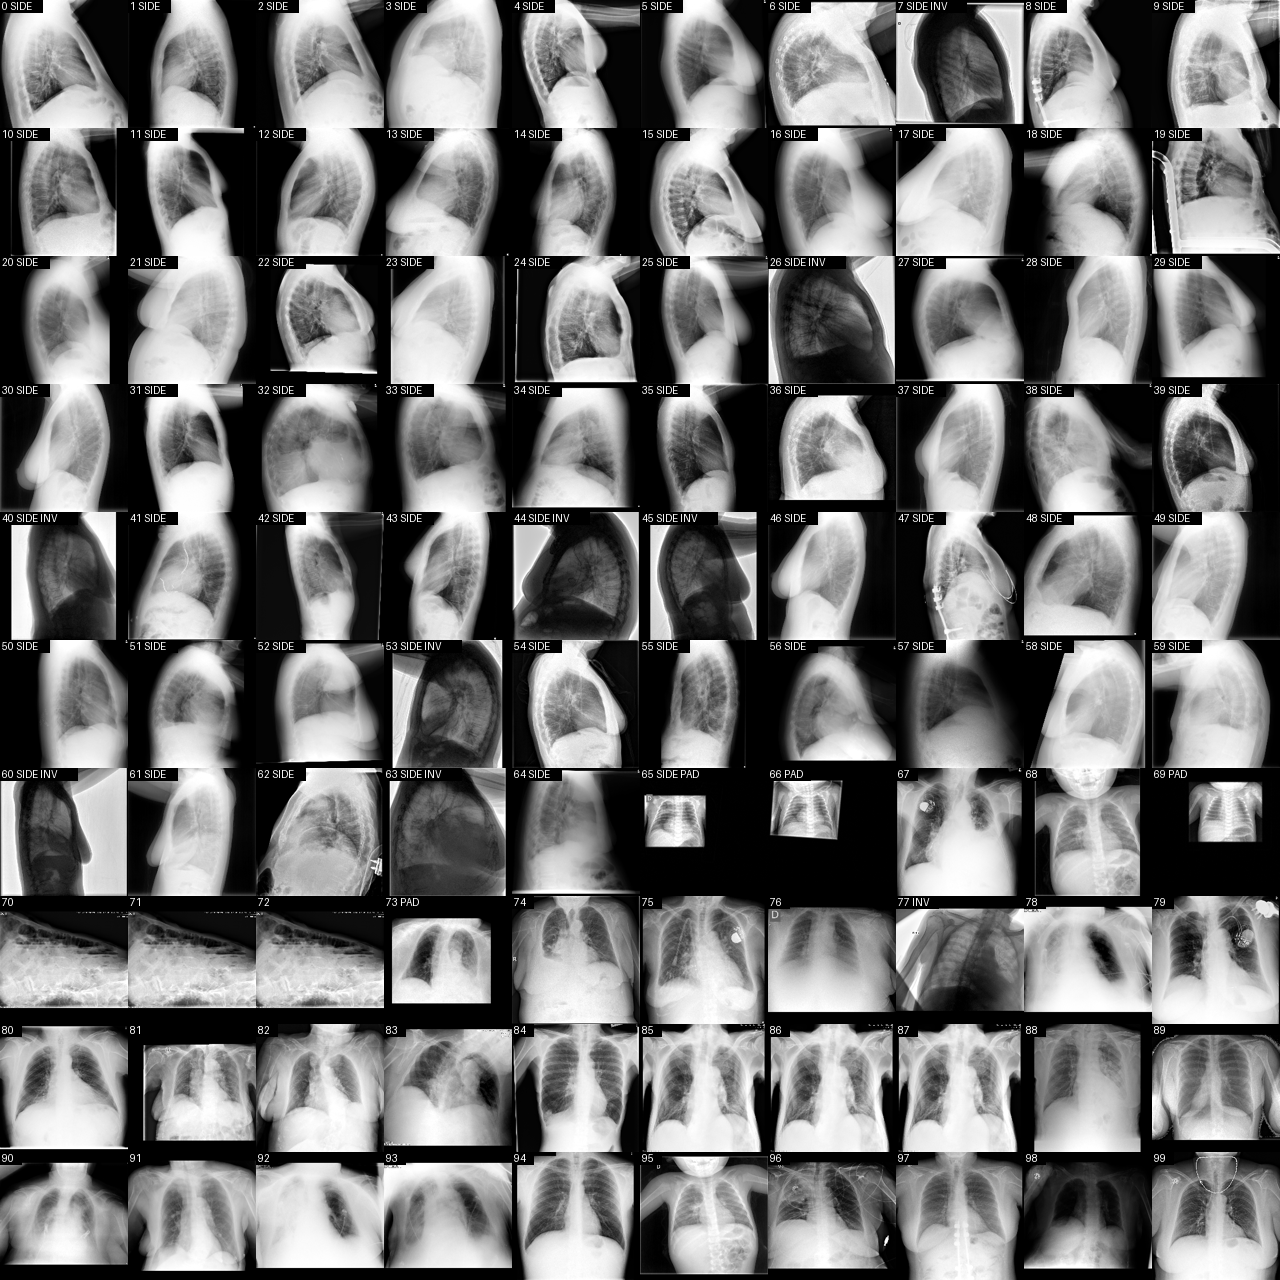

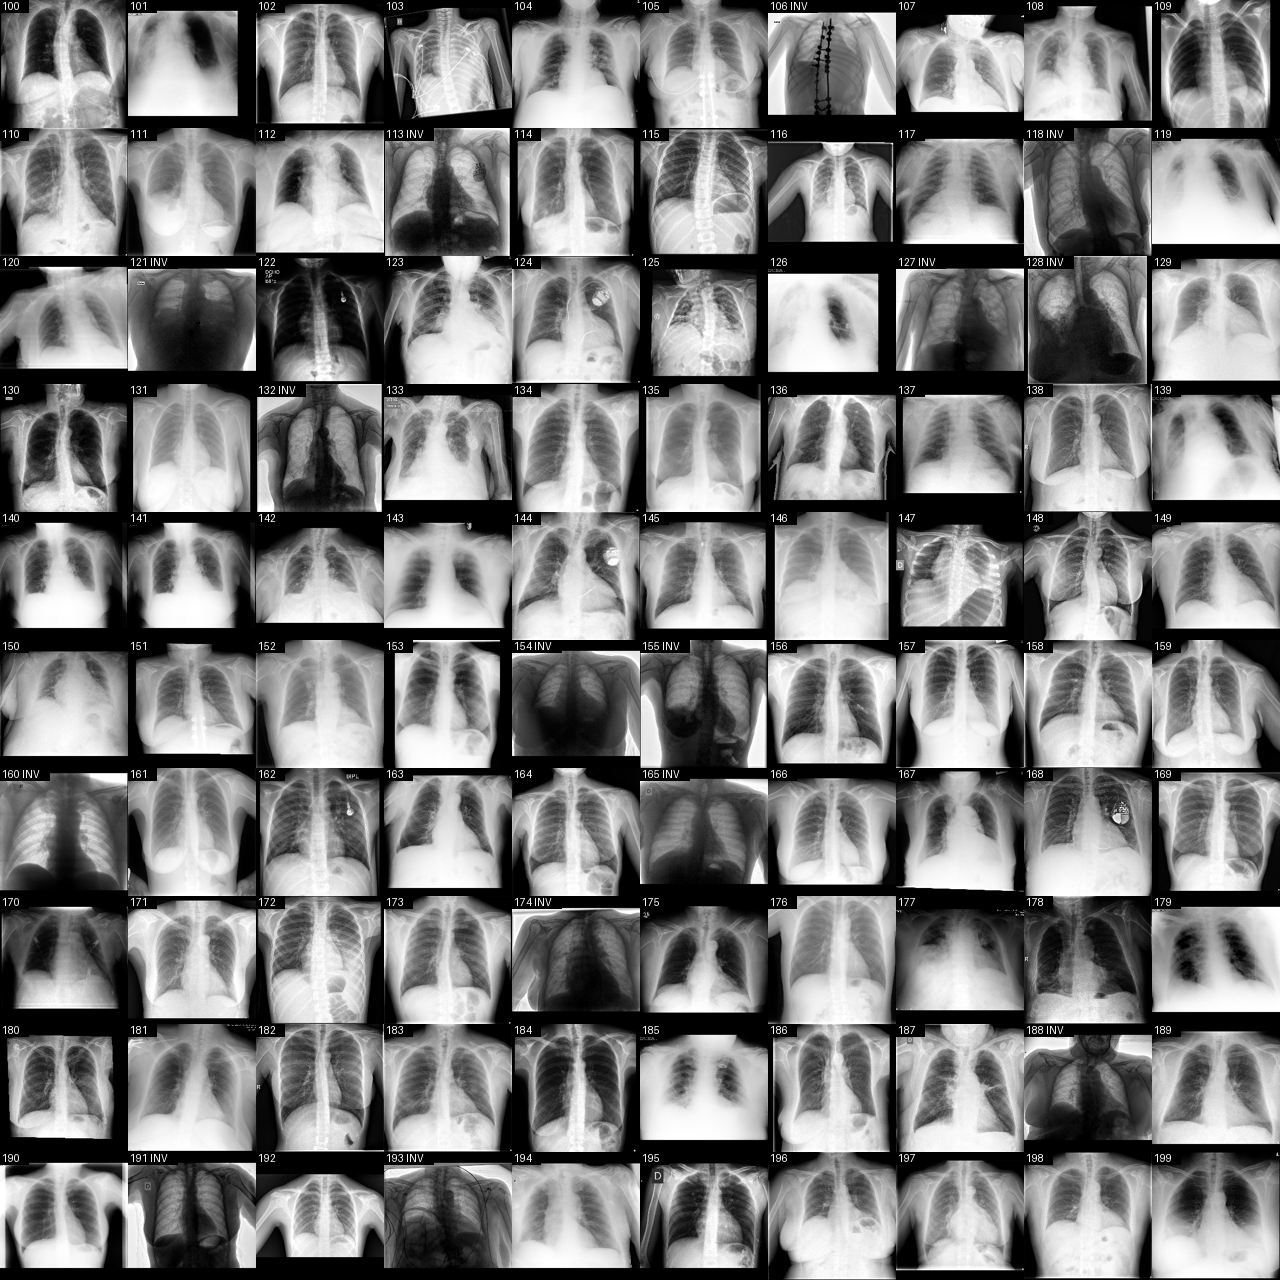

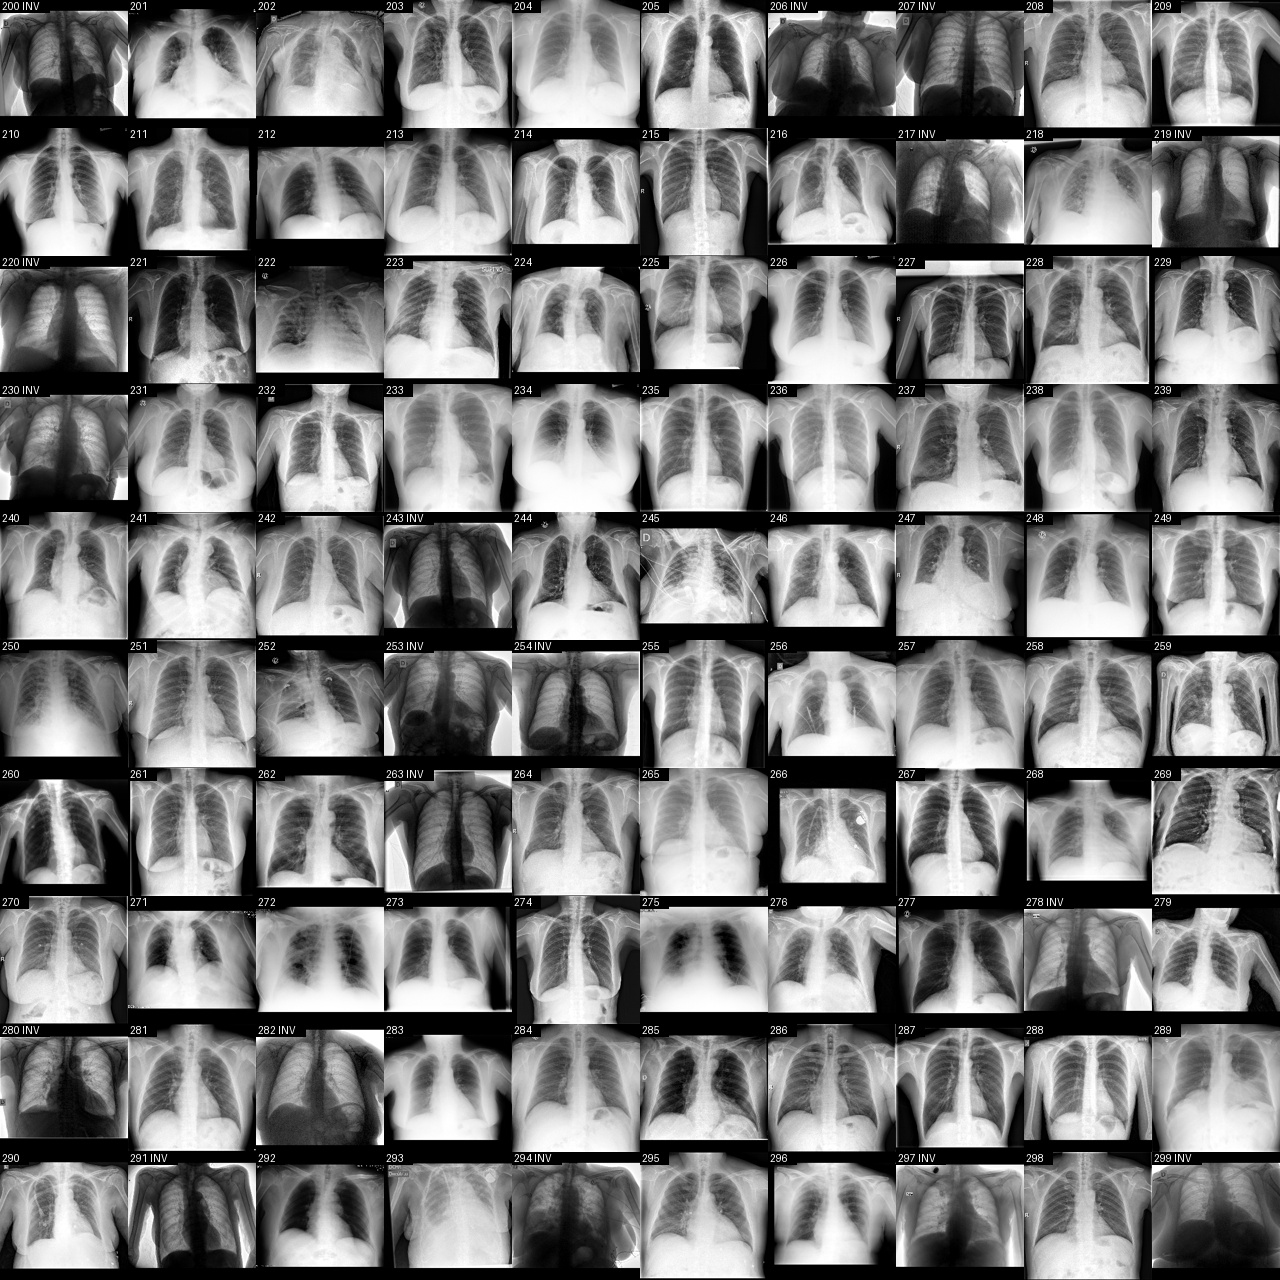

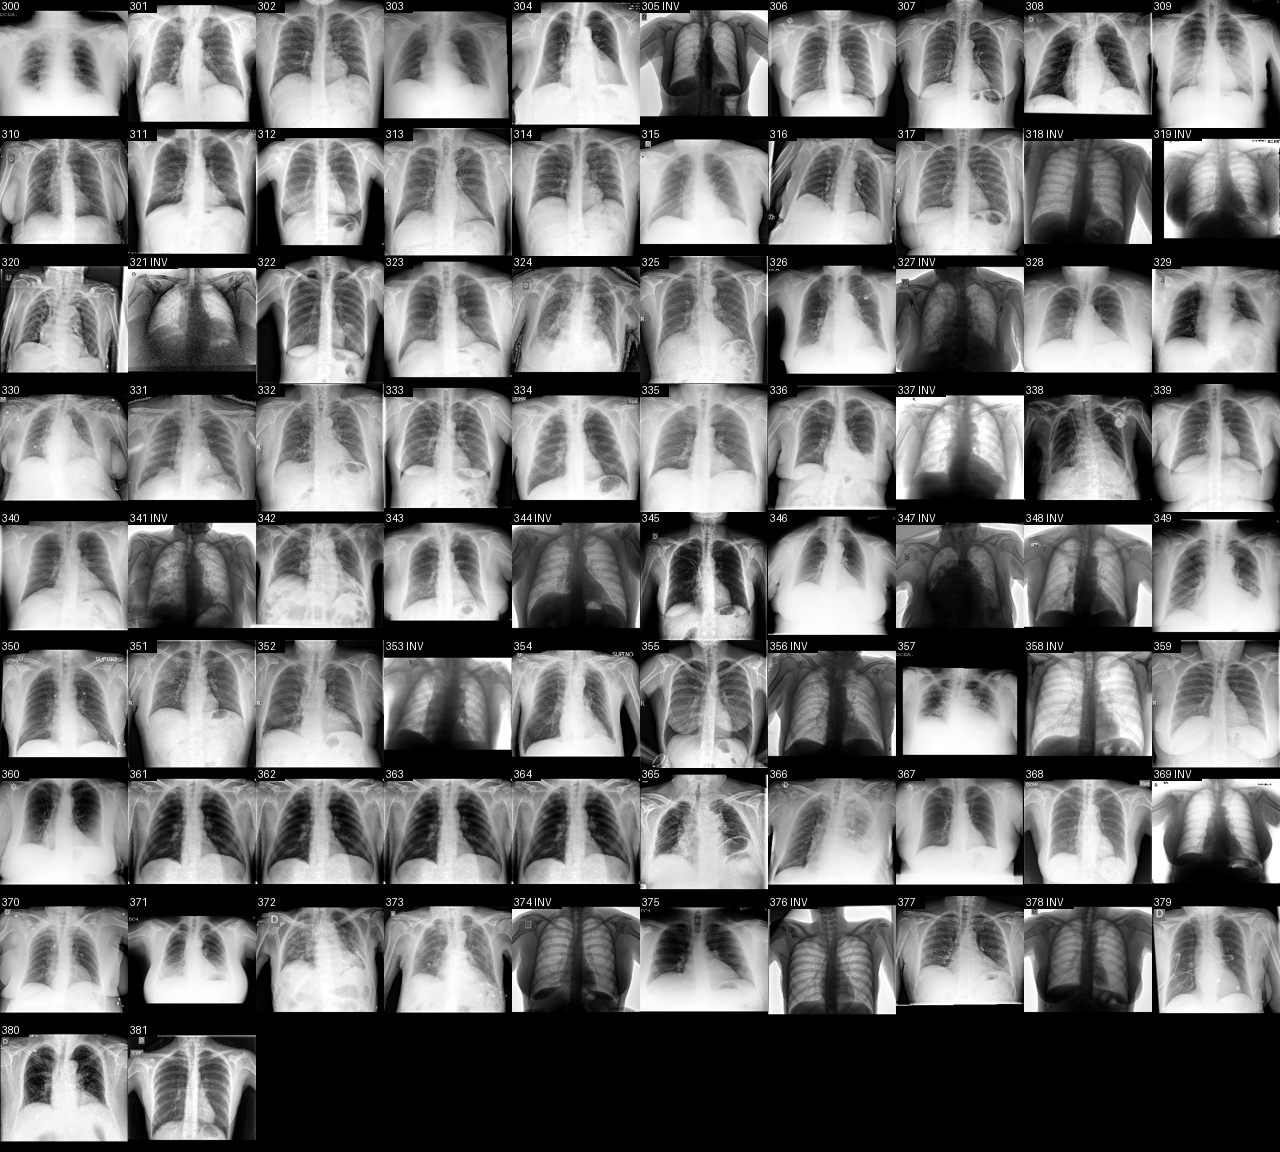

In [ ]:
# STEP 6c: check only the new images; old decisions carry over by filename
import numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

OUT_DIR = Path(r"C:\BIMCV_xray\modelA_224")
REVIEW  = OUT_DIR / "review_auto"
m   = pd.read_csv(OUT_DIR / "modelA_224_manifest.csv")
dec = pd.read_csv(REVIEW / "cleaning_decisions.csv")
m = m.merge(dec[["filename", "keep", "drop_side", "invert"]], on="filename", how="left")
m["is_new"] = ~m["filename"].isin(dec["filename"])
print("old:", (~m["is_new"]).sum(), "| new:", m["is_new"].sum(), m[m["is_new"]].groupby("class").size().to_dict())

# 1) inverted rule (as in 3d), with the template built from your kept old images
S = 64
def crop64(p):
    a = np.asarray(Image.open(p), dtype=np.float32)
    ys, xs = np.where(a > 10)
    if len(ys) == 0:
        return 0.0, np.zeros((S, S), np.float32)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    c = np.asarray(Image.fromarray(a[y0:y1, x0:x1]).resize((S, S)), dtype=np.float32)
    return (y1 - y0) * (x1 - x0) / a.size, (c - c.mean()) / (c.std() + 1e-6)

fracs, crops = zip(*(crop64(OUT_DIR / p) for p in m["rel_path"]))
crops = np.stack(crops)
m["content_frac"] = fracs
old_keep = (~m["is_new"] & m["keep"].eq(True)).values
t = np.median(crops[old_keep], axis=0)
t = (t - t.mean()) / t.std()
m["template_corr"] = (crops * t).mean(axis=(1, 2))
m["auto_invert"] = m["is_new"] & (m["template_corr"] < 0)

# 2) side-view detector, retrained on your earlier decisions
base = tf.keras.applications.MobileNetV2(include_top=False, pooling="avg",
                                         input_shape=(224, 224, 3), weights="imagenet")
def load(path, inv):
    x = tf.cast(tf.io.decode_png(tf.io.read_file(path), channels=3), tf.float32)
    x = tf.where(inv, 255.0 - x, x)
    return tf.keras.applications.mobilenet_v2.preprocess_input(x)

ds = tf.data.Dataset.from_tensor_slices(([str(OUT_DIR / p) for p in m["rel_path"]],
                                         m["auto_invert"].values)).map(load).batch(64)
emb = base.predict(ds, verbose=1)

is_side, is_front = m["drop_side"].eq(True), m["keep"].eq(True)
use = (~m["is_new"] & (is_side | is_front)).values
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1, class_weight="balanced"))
clf.fit(emb[use], is_side[use].astype(int))
m["p_side"] = clf.predict_proba(emb)[:, 1]

# 3) the new images, side views first, with flags
new = m[m["is_new"]].sort_values("p_side", ascending=False).reset_index(drop=True)
new["new_id"] = new.index
flag_parts = [np.where(new["p_side"] > 0.5, "SIDE ", ""),
              np.where(new["auto_invert"], "INV ", ""),
              np.where(new["content_frac"] < 0.6, "PAD", "")]
new["flags"] = ["".join(f).strip() for f in zip(*flag_parts)]
print("SIDE:", (new["p_side"] > 0.5).sum(), "| uncertain (0.2-0.8):", new["p_side"].between(0.2, 0.8).sum(),
      "| INV:", new["auto_invert"].sum(), "| PAD:", (new["content_frac"] < 0.6).sum())

def sheets(rows, N=10, TILE=128):
    for s in range(0, len(rows), N * N):
        chunk = rows.iloc[s:s + N * N]
        img = Image.new("L", (N * TILE, -(-len(chunk) // N) * TILE))
        draw = ImageDraw.Draw(img)
        for k, r in enumerate(chunk.itertuples()):
            x, y = (k % N) * TILE, (k // N) * TILE
            img.paste(Image.open(OUT_DIR / r.rel_path).resize((TILE, TILE)), (x, y))
            label = f"{r.new_id} {r.flags}"
            draw.rectangle([x, y, x + 7 * len(label), y + 12], fill=0)
            draw.text((x + 2, y), label, fill=255)
        display(img)

sheets(new)

For the uncertain ones: if an image labelled SIDE is actually frontal, put its number in NOT_SIDE. If an unlabelled one is actually a side view, put it in DROP. For PAD, drop children and tiny chests. For everything else, just skim the 4 sheets from 6c.

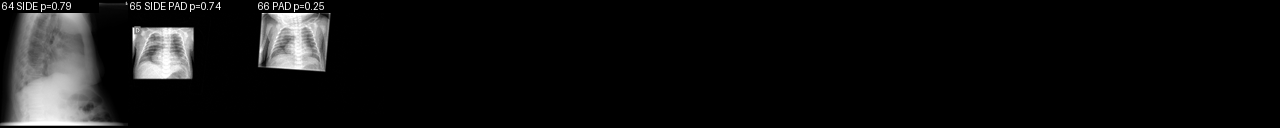

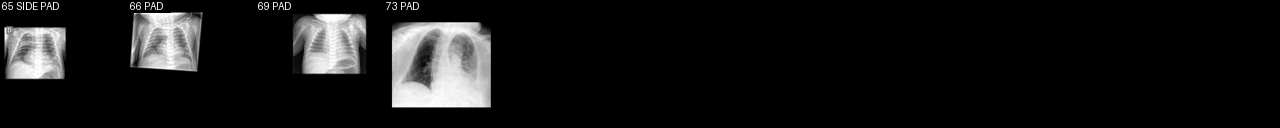

In [ ]:
unsure = new[new["p_side"].between(0.2, 0.8)]
sheets(unsure.assign(flags=unsure["flags"] + " p=" + unsure["p_side"].round(2).astype(str)))

pad = new[new["content_frac"] < 0.6]
sheets(pad)

Flipped new images: 48
Images without a decision (should be 0): 0

Clean images: 3065
Images per split / class:
 class  COVID  Negative
split                 
test     248       188
train   1223       922
val      276       208

Patients per split / class:
 class  COVID  Negative
split                 
test     137       145
train    701       717
val      171       159


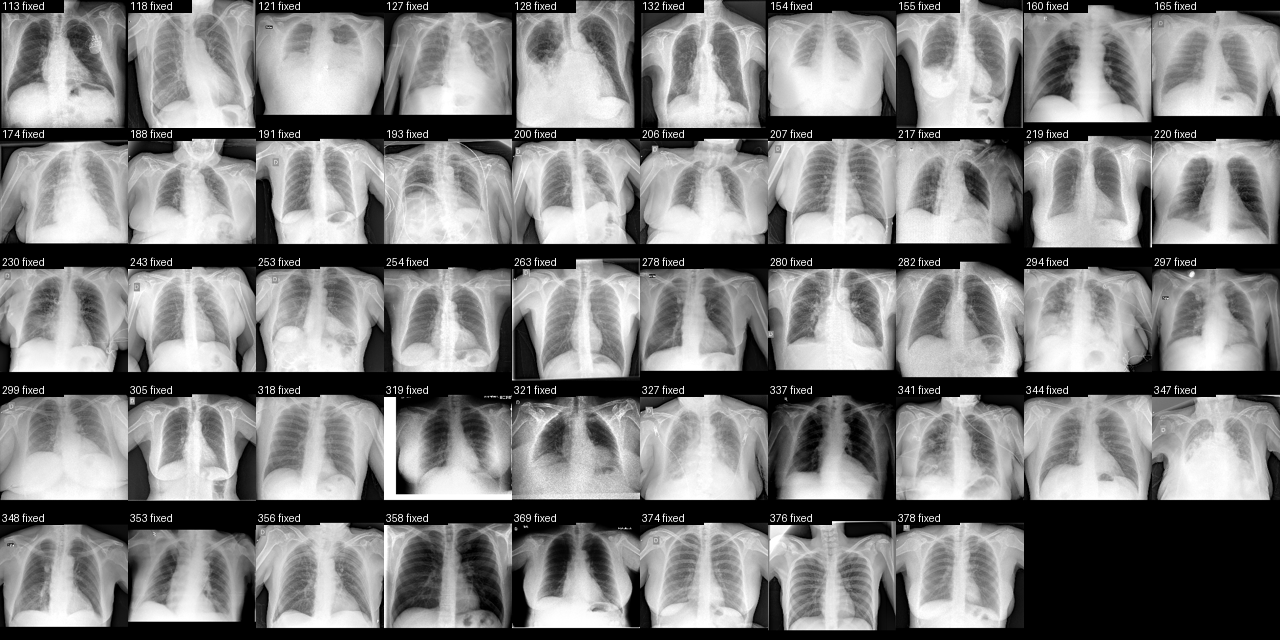

In [ ]:
# STEP 6d: apply decisions to the new images, then write ONE clean manifest for all images
DROP = list(unsure["new_id"]) + list(pad["new_id"]) + [77, 106, 291]

new["drop_side"]   = (new["p_side"] > 0.5) & ~new["new_id"].isin(NOT_SIDE)
new["drop_manual"] = new["new_id"].isin(DROP)
new["invert"]      = new["auto_invert"] & ~new["new_id"].isin(NOT_INV)
new["keep"]        = ~(new["drop_side"] | new["drop_manual"])

# flip the inverted new images from the original file (same as 3g)
orig = pd.read_csv(r"C:\BIMCV_xray\modelA_manifest.csv")[["filename", "filepath"]]
fix = new[new["keep"] & new["invert"]].merge(orig, on="filename")
for r in fix.itertuples():
    Image.fromarray(to_224(255 - robust(read_image(r.filepath)))).save(OUT_DIR / r.rel_path)
print("Flipped new images:", len(fix))

# add the new decisions to the decision record (backup first), so future reruns treat them as old
dec.to_csv(REVIEW / "cleaning_decisions_backup_before_6d.csv", index=False)
keep_cols = ["filename", "keep", "drop_side", "drop_manual", "invert", "p_side", "auto_invert", "content_frac"]
all_dec = pd.concat([dec, new[keep_cols]], ignore_index=True)
all_dec.to_csv(REVIEW / "cleaning_decisions.csv", index=False)

# one clean manifest for everything
m2 = pd.read_csv(OUT_DIR / "modelA_224_manifest.csv").merge(all_dec[["filename", "keep", "invert"]], on="filename", how="left")
print("Images without a decision (should be 0):", m2["keep"].isna().sum())
clean = m2[m2["keep"].eq(True)]
cols = ["rel_path", "filename", "patient_id", "session", "view", "class", "label", "split", "invert"]
clean[cols].to_csv(OUT_DIR / "modelA_224_clean_manifest.csv", index=False)

print("\nClean images:", len(clean))
print("Images per split / class:\n", clean.groupby(["split", "class"]).size().unstack())
print("\nPatients per split / class:\n", clean.groupby(["split", "class"])["patient_id"].nunique().unstack())

sheets(fix.assign(flags="fixed"))                # check the newly flipped ones look normal

In [ ]:
import shutil
shutil.make_archive(r"C:\BIMCV_xray\modelA_V2_224", "zip", r"C:\BIMCV_xray\modelA_V2_224")

'C:\\BIMCV_xray\\modelA_V2_224.zip'

STEPS TO RUN IN COLAB ONLY

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
3065 images
class  COVID  Negative
split                 
test     248       188
train   1223       922
val      276       208
class
COVID       1
Negative    0
Name: label, dtype: int64
batch: (32, 224, 224, 3) min/max: 0.0 1.0


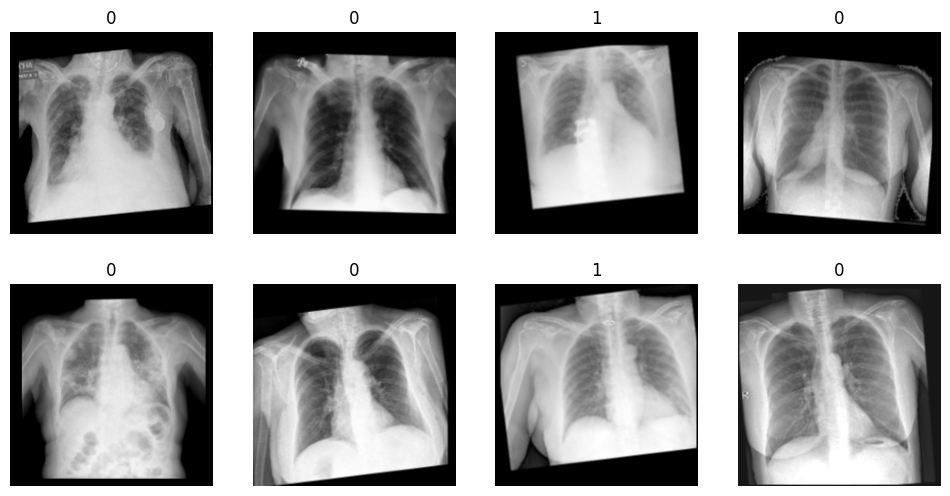

In [ ]:
#STEP4
from google.colab import drive
drive.mount('/content/drive')

import zipfile, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers

ZIP  = "/content/drive/MyDrive/PSUPRProject_2026Sem2/bimcv_xray/modelA_V2_224.zip"
DATA = "/content/modelA__V2_224"                        # unzip to Colab's local disk (much faster than reading from Drive)
zipfile.ZipFile(ZIP).extractall(DATA)

df = pd.read_csv(f"{DATA}/modelA_224_clean_manifest.csv")
df["path"] = DATA + "/" + df["rel_path"]
print(len(df), "images")
print(df.groupby(["split", "class"]).size().unstack())
print(df.groupby("class")["label"].first())         # which class is label 1

IMG, BATCH = 224, 32

def load(path, label):
    x = tf.io.decode_png(tf.io.read_file(path), channels=1)
    x = tf.image.grayscale_to_rgb(x)                  # 3 channels, same as groupmate's make_tensor
    x = tf.cast(x, tf.float32) / 255.0                # 0-1
    return x, tf.cast(label, tf.float32)

# same augmentation as Model B (no horizontal flip)
augment = tf.keras.Sequential([
    layers.RandomRotation(0.02, fill_mode="constant"),
    layers.RandomTranslation(0.05, 0.05, fill_mode="constant"),
    layers.RandomZoom(0.1, fill_mode="constant"),
    layers.RandomBrightness(0.1, value_range=(0, 1)),
])

def make_ds(split, training=False):
    d = df[df["split"] == split]
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label"].values))
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(d), seed=42)
    ds = ds.batch(BATCH)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds("train", training=True)
val_ds   = make_ds("val")
test_ds  = make_ds("test")

x, y = next(iter(train_ds))
print("batch:", x.shape, "min/max:", float(tf.reduce_min(x)), float(tf.reduce_max(x)))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1); plt.imshow(x[i]); plt.title(int(y[i])); plt.axis("off")
plt.show()

In [ ]:
# STEP5
#name="dense" on the 128 layer, so your groupmate’s script finds the encoder
#class weights, since COVID has about 1.7× more training images
#AUC as an extra metric

from tensorflow import keras

SEED = 42
MODEL_DIR = "/content/drive/MyDrive/PSUPRProject_2026Sem2/models"
CKPT = f"{MODEL_DIR}/model_A_final_17oct.keras"
import os; os.makedirs(MODEL_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)
model_A = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu", name="dense"),   # encoder layer for the fusion MLP
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid", name="output"),
])
model_A.summary()

model_A.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")],
)

# class weights: each class counts equally overall
tr = df[df["split"] == "train"]["label"]
class_weight = {c: len(tr) / (2 * (tr == c).sum()) for c in (0, 1)}
print("class_weight:", class_weight)

callbacks = [
    keras.callbacks.ModelCheckpoint(CKPT, monitor="val_loss", save_best_only=True, mode="min", verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, mode="min", restore_best_weights=True, verbose=1),
    keras.callbacks.CSVLogger(CKPT.replace(".keras", "_log.csv")),
]

history_A = model_A.fit(train_ds, validation_data=val_ds, epochs=20,
                        class_weight=class_weight, callbacks=callbacks)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,561 (49.36 MB)

 Trainable params: 12,938,561 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

class_weight: {0: np.float64(1.163232104121475), 1: np.float64(0.8769419460343418)}
Epoch 1/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.5169 - auc: 0.5014 - loss: 0.7106
Epoch 1: val_loss improved from None to 0.67339, saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_A_final_17oct.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_A_final_17oct.keras
68/68 ━━━━━━━━━━━━━━━━━━━━ 35s 345ms/step - accuracy: 0.5301 - auc: 0.5113 - loss: 0.6987 - val_accuracy: 0.5455 - val_auc: 0.5527 - val_loss: 0.6734
Epoch 2/20
67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 0.5294 - auc: 0.5218 - loss: 0.6937
Epoch 2: val_loss did not improve from 0.67339
68/68 ━━━━━━━━━━━━━━━━━━━━ 18s 254ms/step - accuracy: 0.5259 - auc: 0.5168 - loss: 0.6912 - val_accuracy: 0.4938 - val_auc: 0.5328 - val_loss: 0.6809
Epoch 3/20
67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step - accuracy: 0.5130 - auc: 0.5038 - loss: 0.6876
Epoch 3: val_

The key number here is the training AUC, which is only about 0.57, with training loss stuck near 0.69. A loss of 0.69 is what you get from guessing 50/50. So the model is underfitting: it can’t even fit the images it trains on. Overfitting or dirty data would look the opposite, with high train AUC and low val AUC. That points at the model and its settings, not the data. Val AUC jumps around between 0.47 and 0.65 because it’s barely learning anything stable.

In [ ]:
#point to the correct model before running step 7 since step 7 was written after the tuned model
CKPT = f"{MODEL_DIR}/model_A_final_17oct.keras"
log = pd.read_csv(CKPT.replace(".keras", "_log.csv"))

class LoggedHistory:            # Step 7 only uses .history, a dict of lists
    pass
history_A = LoggedHistory()
history_A.history = log.to_dict("list")
print(log.tail(3))

    epoch  accuracy       auc      loss  val_accuracy   val_auc  val_loss
15     15  0.543590  0.578463  0.682231      0.555785  0.632508  0.675589
16     16  0.551515  0.567798  0.685960      0.543388  0.623772  0.667835
17     17  0.553380  0.585458  0.678769      0.522727  0.637916  0.681100


In [ ]:
#STEP 7 Evaluate
# STEP 7: evaluate on the test set
import numpy as np
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

h = history_A.history
plt.figure(figsize=(15, 4))
for i, m in enumerate(["loss", "accuracy", "auc"]):
    plt.subplot(1, 3, i + 1)
    plt.plot(h[m], label="train"); plt.plot(h["val_" + m], label="val")
    plt.title(m); plt.xlabel("epoch"); plt.legend()
plt.show()

best = keras.models.load_model(CKPT)
print("Keras evaluate:", dict(zip(best.metrics_names, best.evaluate(test_ds, verbose=0))))

test_df = df[df["split"] == "test"].copy()
y_true = test_df["label"].values
y_prob = best.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Test images:", len(y_true), "| ROC AUC:", round(roc_auc_score(y_true, y_prob), 4))
print(classification_report(y_true, y_pred, target_names=["Negative", "COVID"], digits=3))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Negative", "COVID"]).plot(cmap="Blues")
plt.title("Model A - test set"); plt.show()

fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.plot(fpr, tpr); plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False positive rate"); plt.ylabel("Sensitivity"); plt.title("ROC - test set"); plt.show()

enc = keras.Model(best.inputs, best.get_layer("dense").output)
print("encoder output:", enc.predict(next(iter(test_ds))[0][:2], verbose=0).shape)   # expect (2, 128)

we'll try tuning it. <br>
BatchNormalization after each conv layer, which makes training from scratch much easier.<br>
A 4th conv block, so the network can see bigger patterns.<br>
GlobalAveragePooling2D instead of Flatten, which cuts about 12 million weights to about 33 thousand in the 128-unit layer.<br>
Learning rate 3e-4, plus ReduceLROnPlateau.
Longer training: 40 epochs, with patience 8.

In [ ]:
# STEP 5B tuned MODEL A
CKPT = f"{MODEL_DIR}/model_A_v2_17oct.keras"     # new name, keeps the first final model

def conv_block(f):
    return [layers.Conv2D(f, (3, 3), padding="same", use_bias=False),
            layers.BatchNormalization(), layers.Activation("relu"),
            layers.MaxPooling2D((2, 2))]

tf.keras.utils.set_random_seed(SEED)
model_A = keras.Sequential(
    [layers.Input(shape=(224, 224, 3))]
    + conv_block(32) + conv_block(64) + conv_block(128) + conv_block(256)
    + [layers.GlobalAveragePooling2D(),
       layers.Dense(128, activation="relu", name="dense"),   # encoder layer for fusion
       layers.Dropout(0.5),
       layers.Dense(1, activation="sigmoid", name="output")]
)
model_A.summary()

model_A.compile(optimizer=keras.optimizers.Adam(learning_rate=3e-4),
                loss="binary_crossentropy",
                metrics=["accuracy", keras.metrics.AUC(name="auc")])

callbacks = [
    keras.callbacks.ModelCheckpoint(CKPT, monitor="val_loss", save_best_only=True, mode="min", verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, mode="min", restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    keras.callbacks.CSVLogger(CKPT.replace(".keras", "_log.csv")),
]

history_A = model_A.fit(train_ds, validation_data=val_ds, epochs=40,
                        class_weight=class_weight, callbacks=callbacks)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,881 (1.61 MB)

 Trainable params: 421,921 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 0.5115 - auc: 0.5132 - loss: 0.7709
Epoch 1: val_loss improved from None to 0.68683, saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_A_v2_17oct.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_A_v2_17oct.keras
68/68 ━━━━━━━━━━━━━━━━━━━━ 34s 347ms/step - accuracy: 0.5096 - auc: 0.5240 - loss: 0.7358 - val_accuracy: 0.5702 - val_auc: 0.5109 - val_loss: 0.6868 - learning_rate: 3.0000e-04
Epoch 2/40
67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step - accuracy: 0.5452 - auc: 0.5675 - loss: 0.6913
Epoch 2: val_loss improved from 0.68683 to 0.68662, saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_A_v2_17oct.keras

Epoch 2: finished saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_A_v2_17oct.keras
68/68 ━━━━━━━━━━━━━━━━━━━━ 18s 256ms/step - accuracy: 0.5422 - auc: 0.5675 - loss: 0.6880 - val_accuracy: 0.5702 - val_

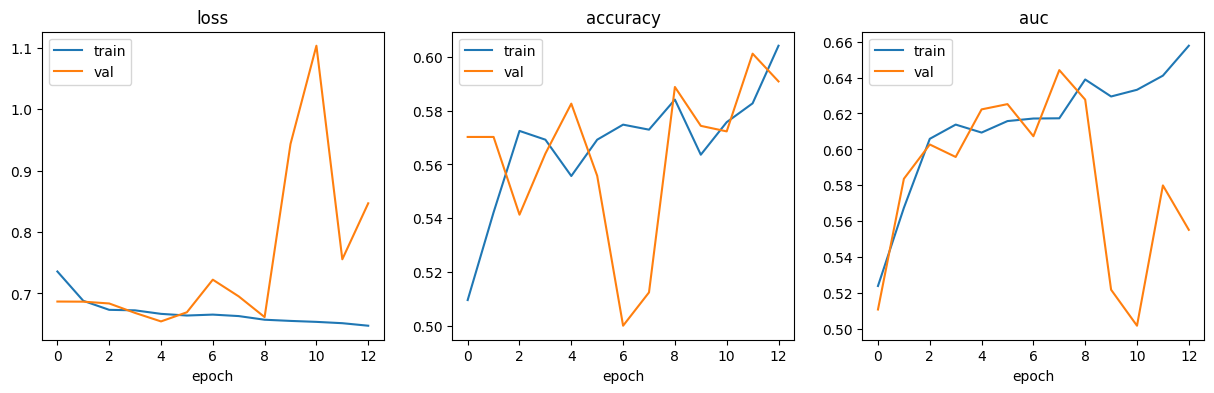

Keras evaluate: {'loss': 0.6544490456581116, 'compile_metrics': 0.6261467933654785}
Test images: 436 | ROC AUC: 0.649
              precision    recall  f1-score   support

    Negative      0.595     0.415     0.489       188
       COVID      0.639     0.786     0.705       248

    accuracy                          0.626       436
   macro avg      0.617     0.601     0.597       436
weighted avg      0.620     0.626     0.612       436



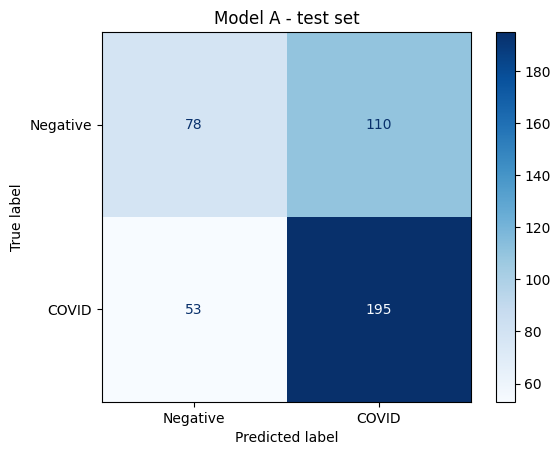

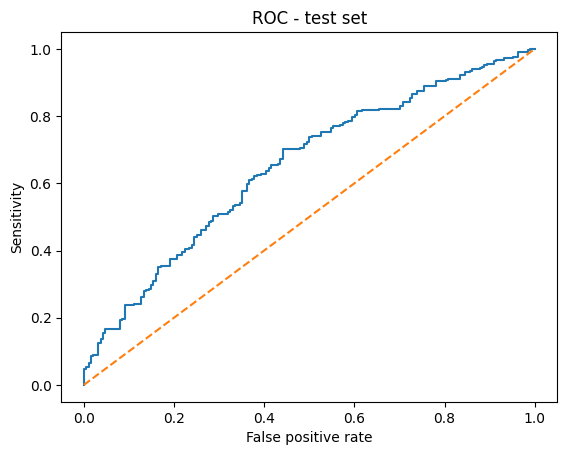

encoder output: (2, 128)


In [ ]:
# STEP 7: evaluate on the test set
import numpy as np
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

h = history_A.history
plt.figure(figsize=(15, 4))
for i, m in enumerate(["loss", "accuracy", "auc"]):
    plt.subplot(1, 3, i + 1)
    plt.plot(h[m], label="train"); plt.plot(h["val_" + m], label="val")
    plt.title(m); plt.xlabel("epoch"); plt.legend()
plt.show()

best = keras.models.load_model(CKPT)
print("Keras evaluate:", dict(zip(best.metrics_names, best.evaluate(test_ds, verbose=0))))

test_df = df[df["split"] == "test"].copy()
y_true = test_df["label"].values
y_prob = best.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Test images:", len(y_true), "| ROC AUC:", round(roc_auc_score(y_true, y_prob), 4))
print(classification_report(y_true, y_pred, target_names=["Negative", "COVID"], digits=3))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Negative", "COVID"]).plot(cmap="Blues")
plt.title("Model A - test set"); plt.show()

fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.plot(fpr, tpr); plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False positive rate"); plt.ylabel("Sensitivity"); plt.title("ROC - test set"); plt.show()

enc = keras.Model(best.inputs, best.get_layer("dense").output)
print("encoder output:", enc.predict(next(iter(test_ds))[0][:2], verbose=0).shape)   # expect (2, 128)

ROC AUC 0.65, accuracy 0.63
Sensitivity (COVID recall) 0.79: it catches 195 of 248 COVID cases.
Specificity (Negative recall) 0.41: it wrongly calls 110 of 188 Negatives COVID.
Encoder output is (2, 128), so the file works for fusion.

What the curves show: the tuning helped. Train AUC now climbs steadily to 0.66, where before it was stuck at 0.57, so the model really is learning. But val loss spikes after epoch 8, and BatchNorm on a small dataset often does that, so early stopping kept epoch 4, when the model had barely started.

My recommendation: keep this as Model A’s result and run the ResNet50 thread next. A test AUC around 0.65 is in the normal range for a CNN trained from scratch on BIMCV. The pretrained models will tell us whether more is possible from this data. If ResNet gets clearly higher, say 0.75 or more, we can come back and push Model A further. If it also lands around 0.65, that’s the ceiling of the data, which is a useful finding for your report.